# 1차시 1206 강효제
데이터명:1206강효제_수행평가1.csv (예, weather2023.xlsx)

### [파일 제출 방법] ###
1. Jupyter Notebook 파일 저장
2. 모든 셀 실행하기
 - 오류 없이 실행되었는지 확인
 - 그래프와 성능평가 결과가 모두 출력되었는지 확인
3. ... → 내보내기(Export) → HTML
4. 아래 2개 파일을 모두 제출 
  - (2-3차시)학번이름(주제).ipynb
  - (2-3차시)학번이름(주제).html


STEP 0. 1차시에 작성한 내용을 옮겨 적으세요. (3점)

1. 탐구 질문:시간대, 기온, 습도, 일사량을 알면 서울시 공공자전거(따릉이)의 시간대별 대여 건수를 예측할 수 있을까?
2. 목표변수(y):Rented Bike Count
3. 특성변수(X)후보:Hour, Temperature(°C), Humidity(%), Solar Radiation (MJ/m2)
4. 문제 유형: 회귀

※ 특성변수(X)는 아직 최종 확정이 아닙니다. 
데이터 전처리와 시각화 결과를 확인한 후 변경할 수 있습니다.

STEP 1. 데이터 불러오기 및 데이터 상태확인· 전처리 하기(5점)

1. 데이터 불러오기
2. 데이터 크기 확인
3. 열이름과 자료형 확인
4. 결측치 확인
5. 중복값 확인
6. 필요하면 전처리 수행


In [95]:
import pandas as pd
import matplotlib.pyplot as plt
# 1~4번, 8~9번은 필수, 6~7번은 필요한 경우 처리
# 1. 데이터 파일 불러오기
bike = pd.read_csv('1206강효제_수행평가1.csv')

# 2. 데이터의 행과 열의 수 확인하기
print(bike.shape)

# 3. 열 이름과 데이터 자료형 확인하기
bike.info()

# 4. 각 열의 결측치 개수 확인하기
print(bike.isnull().sum())

# 5. 중복된 행의 개수 확인하기
print(bike.duplicated().sum())

# 6~7의 결측치 및 중복값이 없는 경우에는 처리하지 않아도 됩니다.
# 6. 필요한 경우 결측치 처리하기


# 7. 필요한 경우 중복 데이터 처리하기


# 8. 분석에 필요하지 않은 열이 있다면 처리하기

bike.drop(['Date','Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day'], axis=1, inplace=True)

# 9. 전처리 후 데이터 상태 다시 확인하기
print(bike.shape)
bike.info()

(1000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       1000 non-null   str    
 1   Rented Bike Count          1000 non-null   int64  
 2   Hour                       1000 non-null   int64  
 3   Temperature(°C)            1000 non-null   float64
 4   Humidity(%)                1000 non-null   int64  
 5   Wind speed (m/s)           1000 non-null   float64
 6   Visibility (10m)           1000 non-null   int64  
 7   Dew point temperature(°C)  1000 non-null   float64
 8   Solar Radiation (MJ/m2)    1000 non-null   float64
 9   Rainfall(mm)               1000 non-null   float64
 10  Snowfall (cm)              1000 non-null   float64
 11  Seasons                    1000 non-null   str    
 12  Holiday                    1000 non-null   str    
 13  Functioning Day            1000 non-null   str   

STEP 2. 특성변수 후보와 목표변수의 관계 시각화하기(4점)

- 1차시에서 선택한 특성변수(X) 후보 중 2개 이상을 선택하여 각각 목표변수(y)와의 관계를 시각화 하세요. 
-예. temp <-> sunshine, humi <-> sunshine

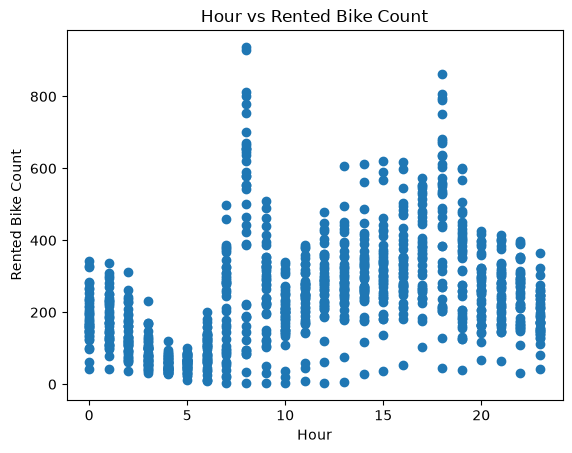

In [96]:
# 시각화1: 특성변수 후보 1과 목표변수의 관계를 확인할 수 있는 그래프 그리기

plt.scatter(bike['Hour'], bike['Rented Bike Count'])
# 그래프 제목 설정하기
plt.title('Hour vs Rented Bike Count')
# x축과 y축 이름 설정하기
plt.xlabel('Hour')
plt.ylabel('Rented Bike Count')

# 그래프 출력하기
plt.show()

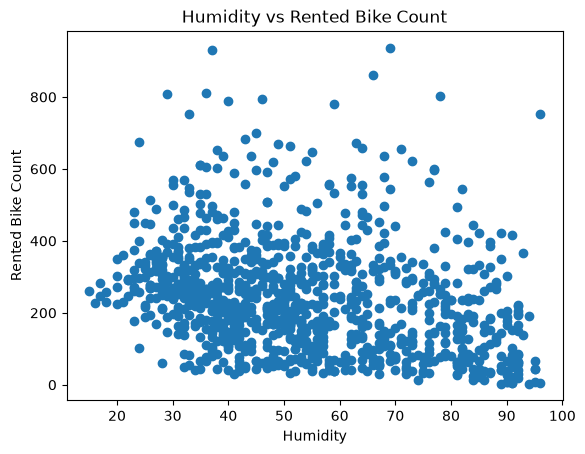

In [97]:
# 시각화2: 특성변수 후보 2와 목표변수의 관계를 확인할 수 있는 그래프 그리기
plt.scatter(bike['Humidity(%)'], bike['Rented Bike Count'])

# 그래프 제목 설정하기
plt.title('Humidity vs Rented Bike Count')

# x축과 y축 이름 설정하기
plt.xlabel('Humidity')
plt.ylabel('Rented Bike Count')

# 그래프 출력하기
plt.show()

STEP 3. 최종 특성변수 X와 목표변수 y 정하기 (2점)

In [98]:

# 최종적으로 사용할 특성변수(X) 선택하기
X = bike[['Hour', 'Temperature(°C)', 'Humidity(%)', 'Solar Radiation (MJ/m2)']]
# 예측할 목표변수(y) 선택하기
y = bike['Rented Bike Count']

STEP 4. 훈련 데이터와 테스트 데이터로 나누기 (3점)

In [99]:
from sklearn.model_selection import train_test_split

# 전체 데이터를 훈련용 데이터와 테스트용 데이터로 나누기
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 훈련 데이터와 테스트 데이터의 크기 확인하기
print('훈련데이터: ', X_train.shape)
print('테스트데이터: ', X_test.shape)

훈련데이터:  (800, 4)
테스트데이터:  (200, 4)


STEP 5. 모델1 선택 및 학습 (4점)
- 모델1 이름: 선형 회귀


In [100]:
# 1. 사용할 머신러닝 모델의 라이브러리 불러오기
from sklearn.linear_model import LinearRegression

# 2. 모델1 생성하기
model1 = LinearRegression()

# 3. 훈련 데이터를 이용하여 모델1 학습시키기
model1.fit(X_train, y_train)

# 4. 테스트 데이터로 예측하기
pred1 = model1.predict(X_test)


STEP 6. 모델 1 성능 평가(3점)

<성능지표> 
회귀: MAE, MSE, RMSE, R² 등

In [101]:
# 모델1의 성능을 평가하기 위한 함수 불러오기
from sklearn.metrics import mean_absolute_error, r2_score

# 성능지표 1 계산하여 출력하기(반드시 성능지표 이름과 결과가 함께 출력되어야 함)
mae1 = mean_absolute_error(y_test, pred1)
print('MAE:', mae1)

# 성능지표 2 계산하여 출력하기(반드시 성능지표 이름과 결과가 함께 출력되어야 함)
r2_1 = r2_score(y_test, pred1)
print('R2:', r2_1)



MAE: 84.89506992933444
R2: 0.3254753060083386


STEP 7. 실제값과 예측값 비교하기(시각화) (2점)

회귀: 실제값과 예측값의 관계를 산점도로 나타내시오.

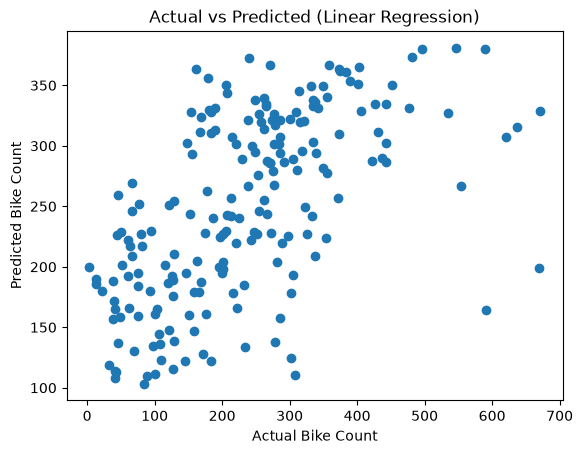

In [102]:

plt.scatter(y_test, pred1)
plt.title('Actual vs Predicted (Linear Regression)')
plt.xlabel('Actual Bike Count')
plt.ylabel('Predicted Bike Count')
plt.show()


STEP 8. 모델2 학습, 예측, 성능평가 (6점)
※ 모델1과 동일한 테스트 데이터 및 성능지표 2개를 사용하세요.

In [103]:
# 1. 모델2에 필요한 라이브러리 불러오기

from sklearn.ensemble import RandomForestRegressor
# 2. 모델2 생성하기
model2 = RandomForestRegressor(n_estimators=100, random_state=42)

# 3. 동일한 훈련 데이터를 이용하여 모델2 학습시키기
model2.fit(X_train, y_train)

# 4. 동일한 테스트 데이터로 예측하기
pred2 = model2.predict(X_test)

# 5. 성능지표 1 계산하여 출력하기(반드시 성능지표 이름과 결과가 함께 출력되어야 함)
mae2 = mean_absolute_error(y_test, pred2)
print('MAE:', mae2)

# 6. 성능지표 2 계산하여 출력하기(반드시 성능지표 이름과 결과가 함께 출력되어야 함)
r2_2 = r2_score(y_test, pred2)
print('R2:', r2_2)



MAE: 56.80831249999999
R2: 0.6759182361414582


STEP 9. 새로운 데이터로 예측하기(3점)

학습에 사용한 특성변수의 값을 직접 정하여 새로운 데이터를 1개 이상 만들고 예측하세요.

In [104]:
# 학습에 사용한 특성변수와 같은 형태로 새로운 데이터 만들기
# ※ 새로운 데이터는 STEP 3에서 선택한 특성변수(X)와 동일한 열 이름 및 개수로 구성하세요.
new_data = pd.DataFrame({
    'Hour': [18],
    'Temperature(°C)': [15.0],
    'Humidity(%)': [50.0],
    'Solar Radiation (MJ/m2)': [1.5]
})

# 모델1 또는 모델2 중 하나를 선택하여 새로운 데이터 예측하기
new_pred = model2.predict(new_data)

# 예측 결과 출력하기
print('예측 자전거 대여량:', new_pred[0])


예측 자전거 대여량: 546.68
